# OutCaRe Outcomes Lab

Change during cardiac rehabilitation (CR) and factors associated with return to work (RTW) and
health-related quality of life 6 months after CR, in the German multi-centre OutCaRe registry.

**Only data source:** Salzwedel et al. (2020), OutCaRe dataset, Zenodo,
https://doi.org/10.5281/zenodo.3605618, CC BY 4.0. Article: https://doi.org/10.1371/journal.pone.0232752.

This notebook runs offline on the local workbook. It shows aggregates only; it never displays
patient level rows. Results are observational associations, not treatment effects or clinical advice.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from IPython.display import Image, display
from outcare_lab import data as D, analysis as A
pd.set_option("display.precision", 2)

## 1. Integrity check and loading

In [2]:
D.verify_raw()
print("md5:", D.md5sum(), "(expected", D.EXPECTED_MD5 + ")")
raw = D.load_raw()
print("shape:", raw.shape)
print("identifier-like columns:", D.identifier_like_columns(raw.columns))
d = D.prepare(raw)

md5: 1d739ee05282cb6133ad415fb0290b23 (expected 1d739ee05282cb6133ad415fb0290b23)


shape: (1262, 76)
identifier-like columns: []


## 2. Sample and sanity checks against the paper

In [3]:
print("n =", len(d))
print(f"age mean {d.age.mean():.1f}, SD {d.age.std():.1f}, range {d.age.min()} to {d.age.max()}")
print("men:", int((d.sex == 1).sum()), " women:", int((d.sex == 2).sum()))
print(f"returned to work: {int(d.rtw_yes.sum())} ({100 * d.rtw_yes.mean():.1f}%)")

n = 1262
age mean 54.2, SD 7.0, range 21 to 65
men: 968  women: 294
returned to work: 864 (68.5%)


In [4]:
A.baseline_table(d)

,variable,n_available,summary
0,Age (years),1262,54.2 (SD 7.0); median 56; range 21 to 65
1,Male sex,1262,968 (76.7%)
2,Female sex,1262,294 (23.3%)
3,Education: <10th grade,1249,209 (16.7%)
4,Education: Secondary school,1249,691 (55.3%)
5,Education: College/University,1249,288 (23.1%)
6,Education: Other,1249,61 (4.9%)
7,Living with family/partner,1248,987 (79.1%)
8,Employed before CR,1248,1127 (90.3%)
9,Sick leave before CR,1248,892 (71.5%)


In [5]:
pd.read_csv(ROOT / "tables" / "t12_paper_sanity_checks.csv")

,check,paper,this_analysis
0,Follow-up patients (n),1262,1262
1,"Age, mean (SD)",54 (7),54.2 (7.0)
2,Age range in file,up to 65 (inclusion),21 to 65
3,"Male, n (%)",77%,968 (76.7%)
4,"Returned to work, n (%)",864 (68.5%),864 (68.5%)
5,Retired at 6 months,67 (5.3%),67 (5.3%)
6,Applied for pension at 6 months,79 (6.3%),79 (6.3%)
7,Unemployed at 6 months,89 (7.1%),89 (7.1%)
8,Sick leave at 6 months,190 (15.1%),190 (15.1%)
9,Readmission at 6 months,194 (15.4%),194 (15.4% of 1260)


## 3. Change from admission (T0) to discharge (T1)

Each row uses only patients with both values.

In [6]:
cont = A.continuous_change(d)
cont[["measure", "n_paired", "mean_t0", "mean_t1", "mean_change", "ci_low", "ci_high", "ses"]]

,measure,n_paired,mean_t0,mean_t1,mean_change,ci_low,ci_high,ses
0,6MWD (m),812,451.83,526.59,74.75,70.70,78.81,0.82
1,Endurance training load (W),1204,48.59,69.73,21.14,19.99,22.30,1.03
2,Maximum exercise capacity (W),790,111.38,130.85,19.47,17.50,21.44,0.52
3,Systolic BP (mmHg),1258,128.84,121.64,-7.20,-8.18,-6.21,-0.39
4,Diastolic BP (mmHg),1258,80.26,75.21,-5.06,-5.70,-4.42,-0.44
5,LDL cholesterol (mmol/l),981,4.59,3.77,-0.82,-0.91,-0.73,-0.32
6,PHQ-9 depression score,1149,6.42,4.36,-2.06,-2.26,-1.86,-0.43
7,HAF-17 heart-focused anxiety (mean),1102,1.46,1.27,-0.19,-0.22,-0.17,-0.32
8,WHO-5 well-being,1180,51.20,69.46,18.26,17.11,19.42,0.71
9,SF-12 PCS,1072,38.95,44.55,5.60,5.10,6.11,0.53


In [7]:
A.binary_change(d)

,measure,n_paired,pct_t0,pct_t1,diff_pp,mcnemar_p
0,Current smoker,1234,34.60,15.15,-19.45,1.28e-51
1,Lifestyle change motivation,1187,79.11,87.36,8.26,1.14e-12
2,Excellent/very good health prognosis,1187,42.88,50.97,8.09,1.94e-08
3,Pension desire,1170,17.52,15.56,-1.97,2.86e-02
4,Negative occupational prognosis,1137,40.72,44.59,3.87,4.87e-04


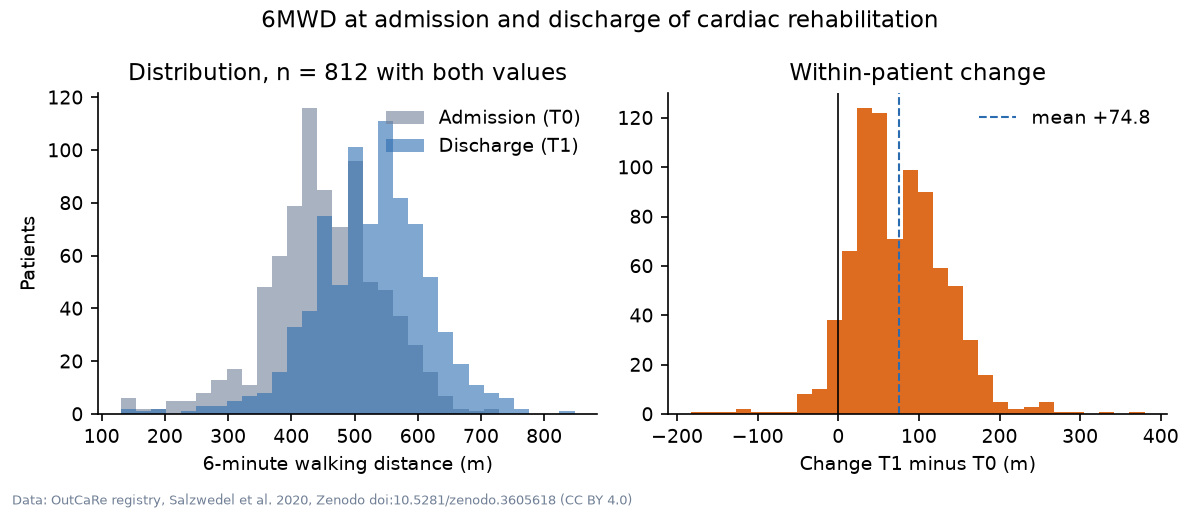

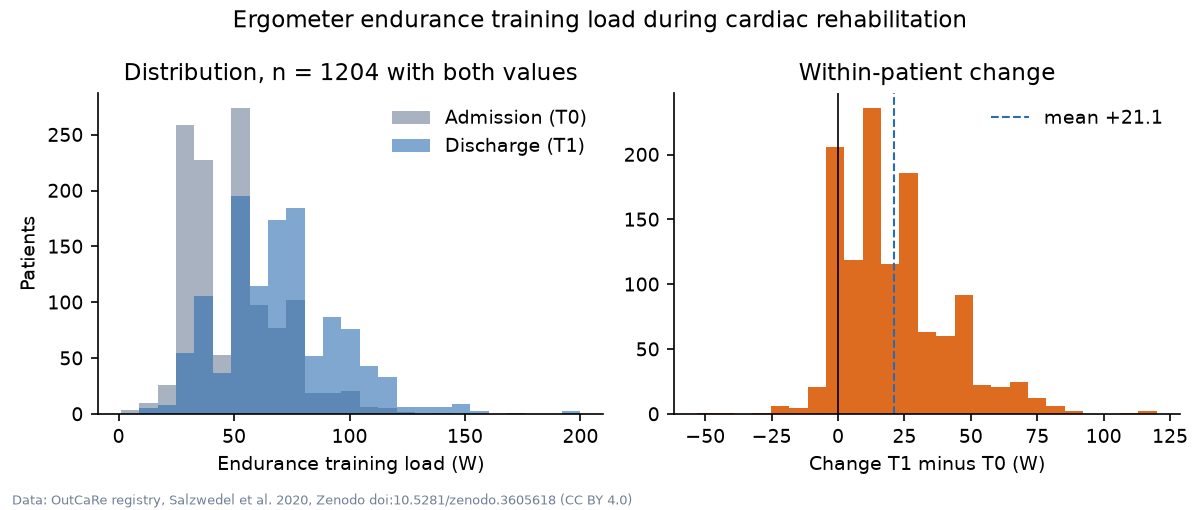

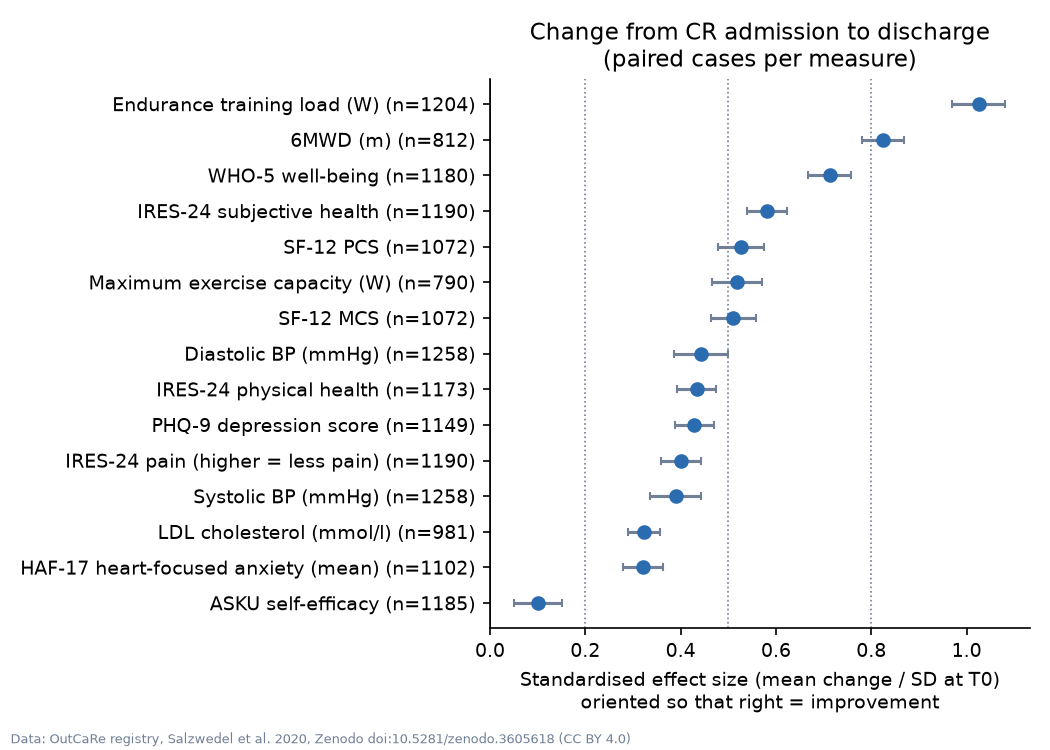

In [8]:
display(Image(str(ROOT / "figures" / "fig02_6mwd_change.png")))
display(Image(str(ROOT / "figures" / "fig03_training_load_change.png")))
display(Image(str(ROOT / "figures" / "fig04_change_effect_sizes.png")))

6MWD is paired for only part of the cohort. The paired subset differs from the rest:

In [9]:
A.selection_6mwd(d)

,characteristic,both_6mwd,not_both_6mwd
0,n,812,450
1,Age (years),54.3,54.1
2,Female (%),23.5,22.9
3,Inpatient CR (%),90.5,94.0
4,ACS indication (%),41.9,35.6
5,Returned to work (%),70.2,65.3
6,SF-12 PCS T0,38.8,39.1
7,Training load T0 (W),52.3,41.5


## 4. Status at 6 months

In [10]:
A.followup_table(d)

,outcome_6_months,n_available,count,pct,ci_low,ci_high,mean,sd
0,Returned to work,1262,864.0,68.46,65.85,70.97,NaN,NaN
1,Retired,1262,67.0,5.31,4.20,6.69,NaN,NaN
2,Applied for/desire pension,1262,79.0,6.26,5.05,7.73,NaN,NaN
3,Unemployed,1262,89.0,7.05,5.77,8.60,NaN,NaN
4,On sick leave,1262,190.0,15.06,13.19,17.13,NaN,NaN
5,Readmission to acute hospital care,1260,194.0,15.40,13.51,17.49,NaN,NaN
6,Health moderately/greatly improved,1256,938.0,74.68,72.20,77.01,NaN,NaN
7,Occupational/physical capacity enhanced,1254,876.0,69.86,67.26,72.33,NaN,NaN
8,SF-12 PCS at 6 months,1181,NaN,NaN,44.92,46.07,45.50,10.05
9,SF-12 MCS at 6 months,1181,NaN,NaN,48.30,49.56,48.93,10.96


In [11]:
A.rtw_by_factor(d)

,factor,level,n,rtw_n,rtw_pct,ci_low,ci_high
0,Pension desire T1,yes,189,54,28.57,22.61,35.39
1,Pension desire T1,no,1000,765,76.50,73.77,79.02
2,Negative occupational prognosis T1,yes,528,257,48.67,44.44,52.93
3,Negative occupational prognosis T1,no,641,556,86.74,83.89,89.15
4,Education,college/university,288,222,77.08,71.89,81.56
5,Education,other,961,633,65.87,62.81,68.80
6,Indication,ACS,500,361,72.20,68.12,75.95
7,Indication,other,762,503,66.01,62.57,69.29
8,Heart failure indication,yes,36,21,58.33,42.20,72.86
9,Heart failure indication,no,1226,843,68.76,66.11,71.29


## 5. Pre-specified models

One fixed set of 18 predictors, no variable selection. Complete case fits are computed here;
the multiple imputation results (20 imputations, predictive mean matching, Rubin's rules) are
produced by `scripts/run_analysis.py` and loaded from `tables/t07_models_rtw_sf12.csv` to keep this
notebook fast. This is not a replication of the paper's backward selected model.

In [12]:
cc_rtw, _, _ = A.complete_case_model(d, "rtw_yes", "logit")
cc_rtw[["label", "estimate", "ci_low", "ci_high", "p", "n"]]

,label,estimate,ci_low,ci_high,p,n
1,Age (per 10 years),1.07,0.84,1.37,5.73e-01,949
2,Female sex,1.22,0.80,1.86,3.67e-01,949
3,College/university education,1.28,0.85,1.93,2.33e-01,949
4,Indication: ACS,0.71,0.49,1.02,6.20e-02,949
5,Indication: chronic heart failure,1.34,0.52,3.45,5.41e-01,949
6,Training load T0 (per 10 W),1.29,1.15,1.45,8.07e-06,949
7,Change in training load T0 to T1 (per 10 W),1.07,0.98,1.17,1.44e-01,949
8,SF-12 PCS T0 (per 10 pts),1.44,1.11,1.86,5.72e-03,949
9,Change in PCS T0 to T1 (per 10 pts),1.13,0.88,1.45,3.29e-01,949
10,SF-12 MCS T0 (per 10 pts),1.53,1.15,2.03,3.27e-03,949


In [13]:
models = pd.read_csv(ROOT / "tables" / "t07_models_rtw_sf12.csv")
mi = models[models.method.str.startswith("multiple")]
mi.pivot_table(index="label", columns="outcome", values="estimate", sort=False)

outcome,rtw_yes,t2pcs12,t2mcs12
label,,,
Age (per 10 years),1.09,-2.98e-01,0.87
Female sex,1.05,6.43e-01,-0.21
College/university education,1.28,2.33e+00,0.23
Indication: ACS,0.69,-8.54e-01,0.14
Indication: chronic heart failure,1.00,-2.17e+00,1.67
Training load T0 (per 10 W),1.23,3.00e-01,-0.19
Change in training load T0 to T1 (per 10 W),1.07,2.91e-01,0.14
SF-12 PCS T0 (per 10 pts),1.49,5.16e+00,1.19
Change in PCS T0 to T1 (per 10 pts),1.14,3.60e+00,1.71


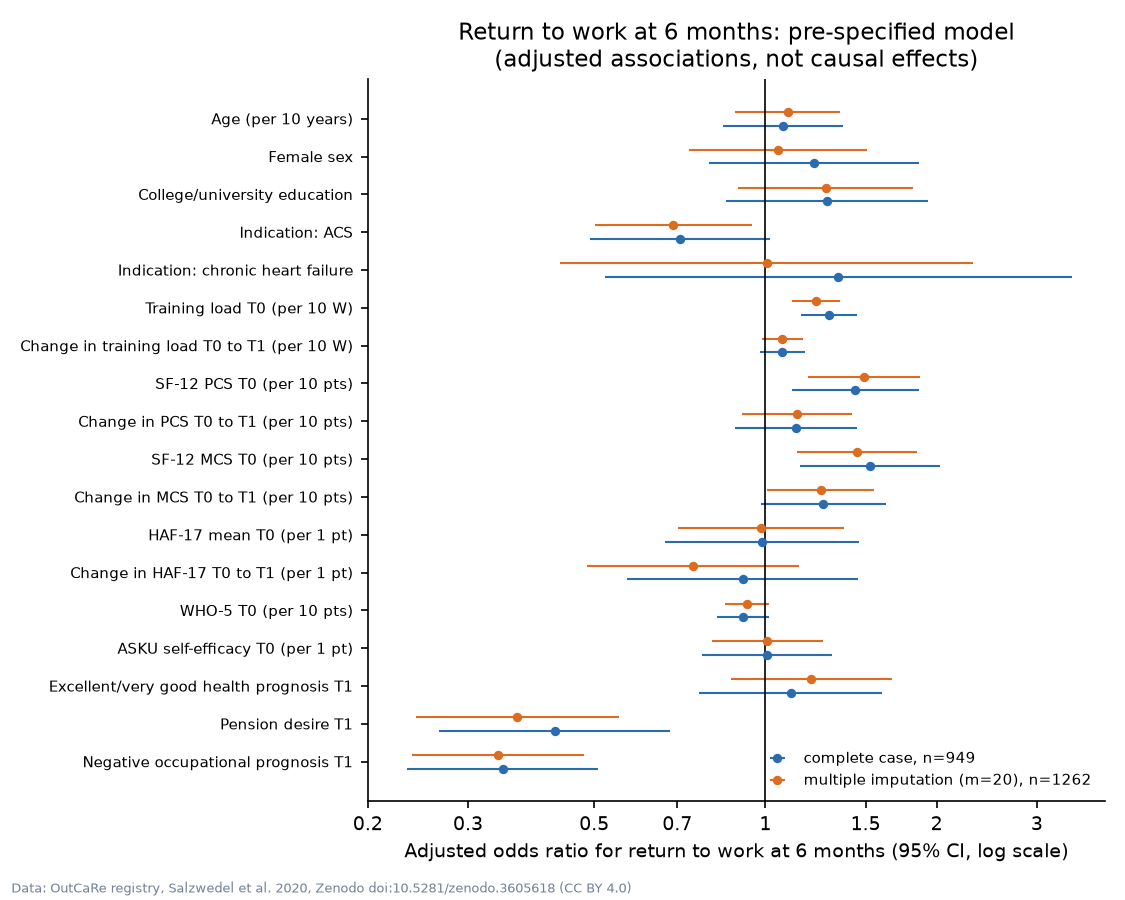

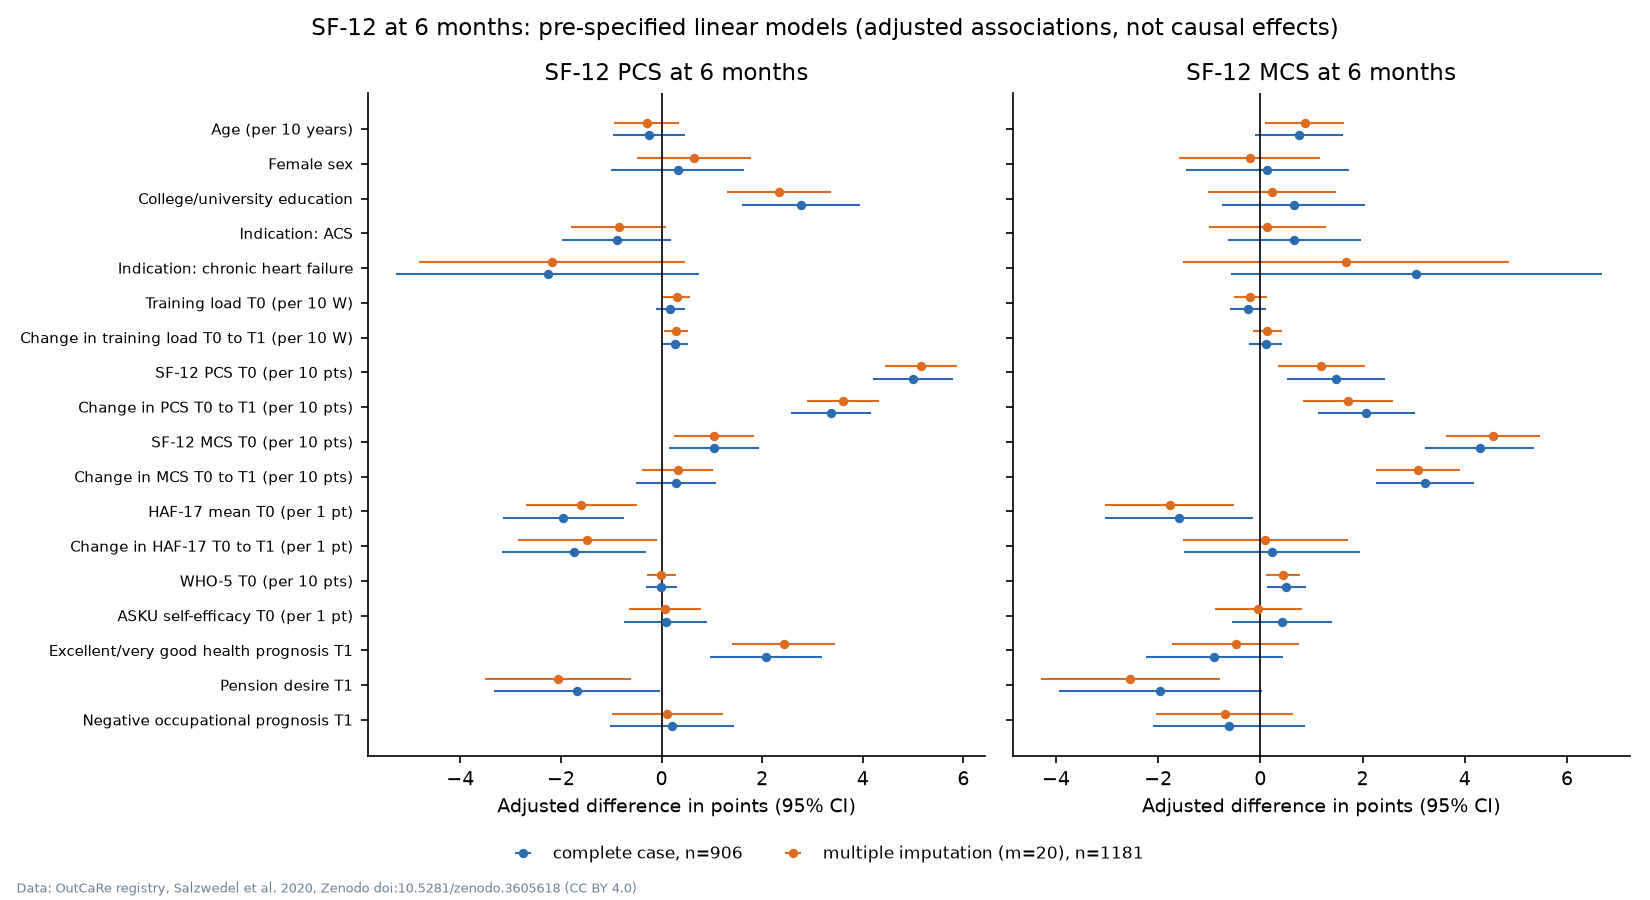

In [14]:
for f in ["fig07_rtw_model_forest.png", "fig08_sf12_model_forest.png"]:
    display(Image(str(ROOT / "figures" / f)))

In [15]:
A.vif_table(d)

,term,label,vif
0,age10,Age (per 10 years),1.11
1,female,Female sex,1.27
2,edu_high,College/university education,1.05
3,acs,Indication: ACS,1.19
4,hf_indication,Indication: chronic heart failure,1.04
5,training0_10,Training load T0 (per 10 W),1.58
6,dtraining_10,Change in training load T0 to T1 (per 10 W),1.26
7,pcs0_10,SF-12 PCS T0 (per 10 pts),3.03
8,dpcs_10,Change in PCS T0 to T1 (per 10 pts),1.85
9,mcs0_10,SF-12 MCS T0 (per 10 pts),4.59


## 6. Exploratory: 6MWD gain and 6 month outcomes (paired subset, minimal adjustment)

In [16]:
A.exploratory_6mwd(d)

,outcome,term,n,scale,estimate,ci_low,ci_high,p
0,rtw_yes,Change in 6MWD (per 50 m),812,odds ratio,1.52,1.30,1.77,1.04e-07
1,t2pcs12,Change in 6MWD (per 50 m),766,points,1.79,1.18,2.39,6.19e-09
2,t2mcs12,Change in 6MWD (per 50 m),766,points,0.72,0.01,1.42,4.57e-02


## 7. Limitations (short)

* Only follow-up responders are in the file (1262 of 1586 enrolled); recruitment quota was 32%.
* German short, mostly inpatient CR for working-age patients.
* Many predictors and outcomes are patient reported.
* 6MWD and some clinical measures are missing for many patients; no centre variable.
* Observational, no control group: associations, not effects.
* Questionnaire scores only; the licensed questionnaires themselves are not included.

See `RESULTS.md` for the full numbers and limitations.